# Predicting Airborne Time

Compare distance-only OLS with multiple OLS, Ridge, Lasso, and Elastic Net using **distance, scheduled elapsed time, airline, and month**.

We use a **0.05% sample**, **seed 42**, and an **80/20 train/test split**. The outcome is `air_time`, measured in minutes.

## 1. Setup

Run this notebook from the DX799 folder.

In [1]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from threadpoolctl import threadpool_limits

SEED = 42
SAMPLE_FRACTION = 0.0005  # 0.05%
DATA_PATH = "datasets/USDOT_1987_2025_Flights_Dataset/flights_2008_2025_cleaned.parquet"
features = ["distance", "scheduled_elapsed_time", "airline", "month"]

## 2. Sample the data

Select random rows without replacement. Reading one Parquet row group at a time avoids loading all 114 million rows into memory. The seed reproduces the same sample from the same file.

In [2]:
parquet = pq.ParquetFile(DATA_PATH)
sample_size = round(parquet.metadata.num_rows * SAMPLE_FRACTION)
rng = np.random.default_rng(SEED)
positions = np.sort(rng.choice(parquet.metadata.num_rows, sample_size, replace=False))
columns = features + ["air_time", "cancelled", "diverted"]

parts = []
offset = 0
for group in range(parquet.num_row_groups):
    end = offset + parquet.metadata.row_group(group).num_rows
    rows = positions[(positions >= offset) & (positions < end)] - offset
    if len(rows):
        table = parquet.read_row_group(group, columns=columns)
        parts.append(table.take(rows).to_pandas())
    offset = end
sample = pd.concat(parts, ignore_index=True)
print(f"Sample: {len(sample):,} flights")

Sample: 57,181 flights


## 3. Keep eligible flights

Use completed, nondiverted flights with valid predictors and airborne time. Scheduled elapsed time includes planned taxi time; airborne time excludes it.

In [3]:
data = sample.loc[(sample["cancelled"] == 0) & (sample["diverted"] == 0), features + ["air_time"]].copy()
data = data.replace([np.inf, -np.inf], np.nan).dropna()
numeric = ["distance", "scheduled_elapsed_time", "air_time"]
data = data.loc[
    (data[numeric] > 0).all(axis=1)
    & data["month"].isin(range(1, 13))
    & data["airline"].str.strip().ne("")
]
print(f"Eligible: {len(data):,}; excluded: {len(sample) - len(data):,}")
data[numeric].describe().round(2)

Eligible: 55,980; excluded: 1,201


,distance,scheduled_elapsed_time,air_time
count,55980.00,55980.00,55980.00
mean,796.03,139.33,110.67
std,592.28,72.72,70.18
min,31.00,21.00,9.00
25%,363.00,86.00,60.00
50%,632.00,120.00,92.00
75%,1028.00,170.00,140.00
max,4983.00,680.00,655.00


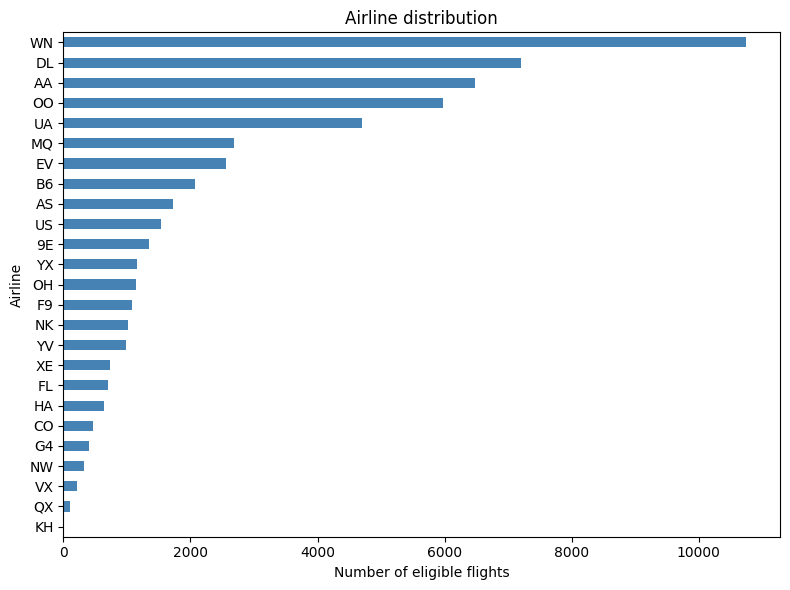

In [4]:
airlines = data["airline"].value_counts().sort_values()
airlines.plot.barh(figsize=(8, 6), color="steelblue")
plt.title("Airline distribution")
plt.xlabel("Number of eligible flights")
plt.ylabel("Airline")
plt.tight_layout()
plt.show()

## 4. Train/test split

All models use the same split. Preprocessing and tuning use training data only.

Training: 44,784; testing: 11,196


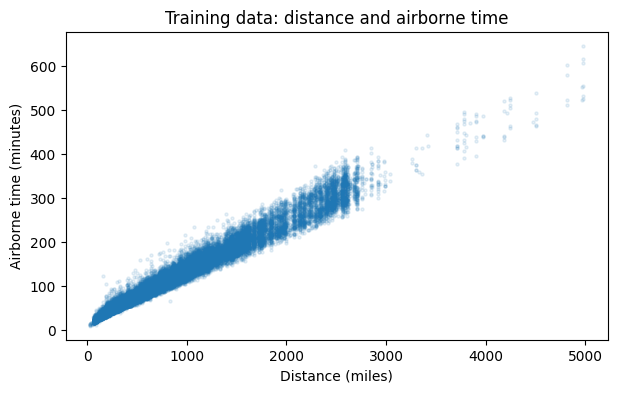

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    data[features], data["air_time"], test_size=0.2, random_state=SEED
)
print(f"Training: {len(X_train):,}; testing: {len(X_test):,}")

plt.figure(figsize=(7, 4))
plt.scatter(X_train["distance"], y_train, s=5, alpha=0.1)
plt.xlabel("Distance (miles)")
plt.ylabel("Airborne time (minutes)")
plt.title("Training data: distance and airborne time")
plt.show()

## 5. Fit the models

- **OLS:** Fits coefficients without a penalty.
- **Ridge:** Shrinks coefficients using an L2 penalty.
- **Lasso:** Uses an L1 penalty and can set coefficients to zero.
- **Elastic Net:** Combines L1 and L2 penalties.

One-hot encode airline and month, dropping one reference category each. Standardize all encoded columns inside each training fold. Five-fold cross-validation selects penalties by lowest RMSE; larger `alpha` means a stronger penalty within a method. The simple OLS model uses distance only.

In [6]:
simple_features = ColumnTransformer([("distance", "passthrough", ["distance"])])
all_features = ColumnTransformer([
    ("numeric", "passthrough", ["distance", "scheduled_elapsed_time"]),
    ("categories", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), ["airline", "month"]),
])

settings = {
    "Simple OLS": (simple_features, LinearRegression(), {}),
    "Multiple OLS": (all_features, LinearRegression(), {}),
    "Ridge": (all_features, Ridge(), {"model__alpha": np.logspace(-4, 4, 17)}),
    "Lasso": (all_features, Lasso(max_iter=10000, tol=1e-7), {"model__alpha": np.logspace(-4, 2, 13)}),
    "Elastic Net": (all_features, ElasticNet(max_iter=10000, tol=1e-7), {
        "model__alpha": np.logspace(-4, 2, 13), "model__l1_ratio": [0.1, 0.5, 0.9]}),
}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
models, tuning = {}, []

with threadpool_limits(limits=1):  # Avoid excess CPU threads during the search.
    for name, (preprocessor, estimator, grid) in settings.items():
        pipeline = Pipeline([("features", preprocessor), ("scale", StandardScaler()), ("model", estimator)])
        search = GridSearchCV(pipeline, grid, cv=cv, scoring="neg_root_mean_squared_error")
        search.fit(X_train, y_train)
        models[name] = search.best_estimator_
        tuning.append({"Model": name, "CV RMSE": -search.best_score_, "Parameters": search.best_params_})
pd.DataFrame(tuning).set_index("Model").round(4)

,CV RMSE,Parameters
Model,,
Simple OLS,12.2898,{}
Multiple OLS,9.0644,{}
Ridge,9.0644,{'model__alpha': 0.31622776601683794}
Lasso,9.0644,{'model__alpha': 0.00031622776601683794}
Elastic Net,9.0644,"{'model__alpha': 0.00031622776601683794, 'mode..."


## 6. Compare test results

**MAE** is average absolute error. **RMSE** gives larger errors more weight. Both are in minutes; lower is better. **R²** measures fit, with 1 representing perfect predictions.

In [7]:
predictions, scores = {}, []
for name, model in models.items():
    prediction = model.predict(X_test)
    predictions[name] = prediction
    coefficients = model.named_steps["model"].coef_
    scores.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, prediction),
        "RMSE": root_mean_squared_error(y_test, prediction),
        "R²": r2_score(y_test, prediction),
        "Predictors": len(coefficients),
        "Zero coefficients": int((coefficients == 0).sum()),
    })
results = pd.DataFrame(scores).set_index("Model")
results.round(4)

,MAE,RMSE,R²,Predictors,Zero coefficients
Model,,,,,
Simple OLS,8.6113,12.3725,0.9678,1,0
Multiple OLS,6.4931,9.0732,0.9827,37,0
Ridge,6.4930,9.0732,0.9827,37,0
Lasso,6.4929,9.0732,0.9827,37,0
Elastic Net,6.4927,9.0732,0.9827,37,0


### Regression coefficients

Coefficients are converted back to original units. Airline effects are relative to **9E**, and month effects to **January**, holding other inputs fixed. A dash means the predictor was not included; it is different from a zero coefficient.

In [8]:
coefficient_columns = {}
for name, model in models.items():
    encoder = model.named_steps["features"]
    scaler = model.named_steps["scale"]
    regression = model.named_steps["model"]
    names = [column.split("__", 1)[1] for column in encoder.get_feature_names_out()]
    values = regression.coef_ / scaler.scale_
    intercept = regression.intercept_ - np.dot(values, scaler.mean_)
    coefficient_columns[name] = pd.Series([intercept, *values], index=["Intercept", *names])

coefficients = pd.DataFrame(coefficient_columns)
coefficients.style.format(precision=5, na_rep="—")

,Simple OLS,Multiple OLS,Ridge,Lasso,Elastic Net
Intercept,17.84904,-13.58222,-13.57711,-13.53229,-13.51450
airline_AA,—,2.19648,2.19557,2.14584,2.14690
airline_AS,—,5.06768,5.06641,5.01564,5.01520
airline_B6,—,3.97341,3.97249,3.92197,3.92305
airline_CO,—,4.58589,4.58513,4.53268,4.53466
airline_DL,—,0.98139,0.98040,0.93090,0.93160
airline_EV,—,3.37594,3.37470,3.32530,3.32485
airline_F9,—,2.61720,2.61609,2.56516,2.56544
airline_FL,—,6.18802,6.18644,6.13548,6.13371
airline_G4,—,5.97094,5.96906,5.91723,5.91426


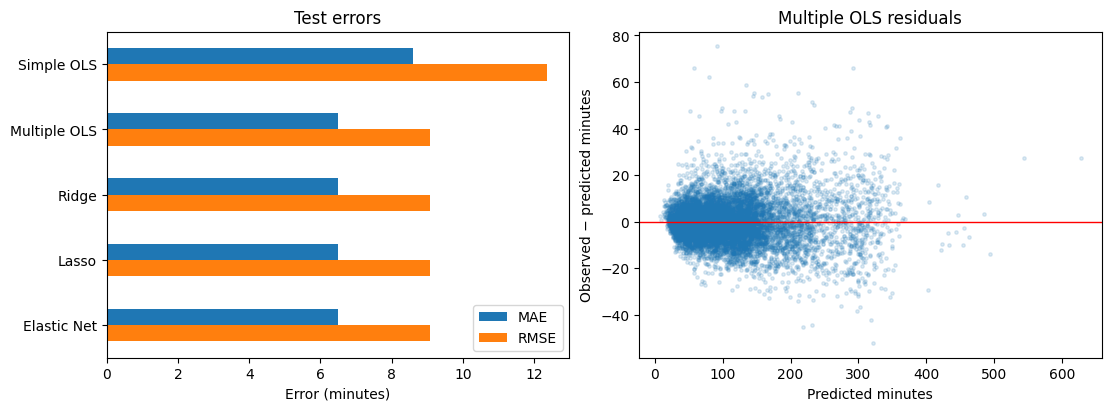

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
results[["MAE", "RMSE"]].plot.barh(ax=axes[0])
axes[0].invert_yaxis()
axes[0].set(title="Test errors", xlabel="Error (minutes)", ylabel="")

prediction = predictions["Multiple OLS"]
axes[1].scatter(prediction, y_test - prediction, s=6, alpha=0.15)
axes[1].axhline(0, color="red", linewidth=1)
axes[1].set(title="Multiple OLS residuals", xlabel="Predicted minutes", ylabel="Observed − predicted minutes")
plt.show()

## 7. Findings

- Adding the three predictors reduced RMSE from **12.37 to 9.07 minutes**, an improvement of about **27%**. Multiple OLS achieved **MAE 6.49 minutes** and **R² 0.9827**.
- Ridge, Lasso, and Elastic Net performed almost identically to multiple OLS. Adding information mattered more than adding a penalty.
- One-hot encoding produced **37 predictors**: two numeric columns, 24 airline indicators, and 11 month indicators. All were retained at the selected penalties. Lasso can remove coefficients, but does not always do so.

**Limitations:** This reuses one historical random split and does not test future flights. Some airlines have few observations, and the cleaned data include reconstructed durations. Results describe prediction and association, not causation.